# This notebook attempts to find the best spot for the 150 mm lens

## The lens is placed about 203 mm frpom the back surface of the vapour cell.

# Code to overlay the fitting

In [29]:
import csv
import re
import shutil
import tempfile
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.special import wofz


# ============================================================
# SETTINGS
# ============================================================

DATA_FOLDER = Path(
    "/Volumes/Physics-Photonics/Group/Compact components/"
    "2PAC/Data/20261123/27mW_2"
)

DATA_FILES = [
    DATA_FOLDER / f"150mm_{number}.csv"
    for number in range(2, 7)
]

CHANNEL = 2

# Keep these identical to your single-file fitting settings.
REVERSE_SIGNAL = True
SIGNAL_POLARITY = 1

CROP_FRACTION = (0.2, 0.8)
FIT_RANGE_MHZ = (-30, 50)

PEAK_HEIGHT = 0.3
PEAK_WIDTH_SAMPLES = 10
PEAK_DISTANCE_FRACTION = 0.05

CALIBRATION_SEPARATION_MHZ = 14.412

# None selects the first and last detected calibration peaks,
# matching your original single-file code.
# Alternatively, specify numbered peaks, e.g. (1, 2).
CALIBRATION_PAIR = None

SHOW_CALIBRATION_PLOTS = False

# Plotting only: shift each spectrum so the selected fitted
# peak is centred at zero. Does not change the fits.
ALIGN_TO_SELECTED_PEAK = False

# Original parameter-block numbering is preserved.
# Peak 1 = first four entries of INITIAL_GUESS.
PEAK_FOR_AVERAGE = 1

SAVE_RESULTS = True
MAX_FIT_EVALUATIONS = 80000

# Each peak:
# area, centre (MHz), Gaussian sigma (MHz),
# Lorentzian gamma/HWHM (MHz).
INITIAL_GUESS = np.array([
    4.00,  0.5, 1.0, 1.0,   # Peak 1
    2.00, 15.0, 1.0, 1.0,   # Peak 2
    1.05, 25.0, 1.0, 1.0,   # Peak 3
    1.00, 32.0, 1.0, 1.0,   # Peak 4
    0.10,                    # Constant background
], dtype=float)

COLORS = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
    "#E69F00",
]


# ============================================================
# READ OSCILLOSCOPE CSV
# ============================================================

def clean_column_name(name):
    name = str(name).strip().lstrip("%#").strip().lower()
    name = re.sub(r"\([^)]*\)|\[[^]]*\]", "", name)
    return re.sub(r"[^a-z0-9]", "", name)


def read_scope_csv(file_path, channel):
    time_aliases = {"xaxis", "time", "times", "timeseconds"}
    header_row = None

    with file_path.open(
        "r", encoding="utf-8-sig", newline=""
    ) as handle:
        for row_number, row in enumerate(csv.reader(handle)):
            headings = [clean_column_name(value) for value in row]

            if any(value in time_aliases for value in headings):
                header_row = row_number
                break

    if header_row is None:
        raise ValueError(
            f"No time-column header found in {file_path.name}."
        )

    df = pd.read_csv(
        file_path,
        skiprows=header_row,
        encoding="utf-8-sig",
    )

    column_lookup = {
        clean_column_name(column): column
        for column in df.columns
    }

    time_column = next(
        (
            original
            for cleaned, original in column_lookup.items()
            if cleaned in time_aliases
        ),
        None,
    )

    signal_aliases = [
        str(channel),
        f"ch{channel}",
        f"channel{channel}",
        f"input{channel}",
        f"signal{channel}",
    ]

    signal_column = next(
        (
            column_lookup[alias]
            for alias in signal_aliases
            if alias in column_lookup
        ),
        None,
    )

    if time_column is None or signal_column is None:
        raise ValueError(
            f"Could not identify time and channel {channel}.\n"
            f"Available columns: {list(df.columns)}"
        )

    numeric = df[[time_column, signal_column]].apply(
        pd.to_numeric,
        errors="coerce",
    )

    values = numeric.to_numpy(dtype=float)
    values = values[np.isfinite(values).all(axis=1)]

    if len(values) < 50:
        raise ValueError("Too few valid numeric data points.")

    print(f"Time column: {time_column}")
    print(f"Signal column: {signal_column}")
    print(f"Numeric samples: {len(values)}")

    return values[:, 0], values[:, 1]


# ============================================================
# PREPROCESS AND CALIBRATE
# ============================================================

def extract_and_calibrate(time, signal, file_name):
    signal = SIGNAL_POLARITY * signal.copy()

    # Intentionally matches the original single-file code:
    # reverse the signal while retaining the time array.
    if REVERSE_SIGNAL:
        signal = np.flip(signal)

    start = int(CROP_FRACTION[0] * len(signal))
    stop = int(CROP_FRACTION[1] * len(signal))

    time = time[start:stop]
    signal = signal[start:stop]

    if len(signal) < 20:
        raise ValueError(
            f"{file_name}: too few samples after cropping."
        )

    signal = signal - np.mean(signal[:10])
    maximum = np.max(signal)

    if maximum <= 0:
        raise ValueError(
            f"{file_name}: no positive peak after background "
            "subtraction. Check SIGNAL_POLARITY."
        )

    signal = signal / maximum

    peaks, _ = find_peaks(
        signal,
        height=PEAK_HEIGHT,
        width=PEAK_WIDTH_SAMPLES,
        distance=max(
            1,
            int(len(signal) * PEAK_DISTANCE_FRACTION),
        ),
    )

    if len(peaks) < 2:
        raise ValueError(
            f"{file_name}: only {len(peaks)} calibration peaks "
            "detected. Check crop, polarity and peak thresholds."
        )

    if CALIBRATION_PAIR is None:
        first, second = peaks[0], peaks[-1]
        selected_numbers = (1, len(peaks))

        if len(peaks) > 2:
            print(
                "WARNING: more than two calibration candidates "
                "were detected. Using the first and last, as in "
                "your original code. Check the selected pair."
            )
    else:
        pair = np.asarray(CALIBRATION_PAIR)

        if (
            pair.shape != (2,)
            or not np.issubdtype(pair.dtype, np.integer)
            or pair[0] == pair[1]
            or np.any(pair < 1)
            or np.any(pair > len(peaks))
        ):
            raise ValueError(
                "CALIBRATION_PAIR must contain two different "
                "valid peak numbers."
            )

        first, second = np.sort(peaks[pair - 1])
        selected_numbers = tuple(sorted(pair))

    print(
        f"Detected {len(peaks)} peaks; "
        f"calibrating with peaks {selected_numbers}."
    )

    if SHOW_CALIBRATION_PLOTS:
        fig_cal, ax = plt.subplots(figsize=(10, 4))

        ax.plot(time, signal, color="black")
        ax.scatter(
            time[peaks], signal[peaks],
            color="red", marker="x",
        )

        for number, index in enumerate(peaks, start=1):
            ax.annotate(
                str(number),
                (time[index], signal[index]),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
            )

        ax.scatter(
            time[[first, second]],
            signal[[first, second]],
            s=100,
            facecolors="none",
            edgecolors="blue",
            label="Selected calibration pair",
        )

        ax.axhline(
            PEAK_HEIGHT, color="grey", linestyle=":"
        )
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Normalised signal")
        ax.set_title(f"Calibration: {file_name}")
        ax.legend()
        ax.grid(alpha=0.3)
        fig_cal.tight_layout()

    delta_time = time[second] - time[first]

    if delta_time == 0:
        raise ValueError("Calibration peaks have identical times.")

    # Same frequency convention as the single-file code.
    frequency = (
        -(time - time[second])
        * CALIBRATION_SEPARATION_MHZ
        / delta_time
    )

    keep = (
        (frequency > FIT_RANGE_MHZ[0])
        & (frequency < FIT_RANGE_MHZ[1])
    )

    frequency = frequency[keep]
    signal = signal[keep]

    if len(frequency) <= len(INITIAL_GUESS):
        raise ValueError(
            f"{file_name}: too few points in the fitting range."
        )

    order = np.argsort(frequency)
    return frequency[order], signal[order]


# ============================================================
# FOUR-VOIGT MODEL
# ============================================================

def voigt_onepeak(x, area, centre, sigma, gamma):
    z = (
        (x - centre) + 1j * gamma
    ) / (sigma * np.sqrt(2))

    return (
        area * np.real(wofz(z))
        / (sigma * np.sqrt(2 * np.pi))
    )


def voigt_bkgd(x, *parameters):
    model = np.full_like(x, parameters[-1], dtype=float)

    for peak_index in range(4):
        offset = 4 * peak_index
        model += voigt_onepeak(
            x, *parameters[offset:offset + 4]
        )

    return model


# ============================================================
# LINEWIDTHS AND FIT UNCERTAINTIES
# ============================================================

def linewidth_results(sigma, gamma, width_covariance):
    gaussian_factor = 2 * np.sqrt(2 * np.log(2))

    gaussian_fwhm = gaussian_factor * sigma
    lorentzian_fwhm = 2 * gamma

    # Same approximation as your single-file code.
    root = np.sqrt(
        0.2169 * lorentzian_fwhm**2
        + gaussian_fwhm**2
    )

    voigt_fwhm = 0.5343 * lorentzian_fwhm + root

    gaussian_gradient = np.array([gaussian_factor, 0.0])
    lorentzian_gradient = np.array([0.0, 2.0])

    voigt_gradient = np.array([
        gaussian_factor * gaussian_fwhm / root,
        2 * (
            0.5343
            + 0.2169 * lorentzian_fwhm / root
        ),
    ])

    def propagated_error(gradient):
        if not np.isfinite(width_covariance).all():
            return np.nan

        variance = gradient @ width_covariance @ gradient
        return np.sqrt(max(0.0, variance))

    return {
        "Gaussian_FWHM_kHz": gaussian_fwhm * 1000,
        "Gaussian_FWHM_error_kHz":
            propagated_error(gaussian_gradient) * 1000,
        "Lorentzian_FWHM_kHz": lorentzian_fwhm * 1000,
        "Lorentzian_FWHM_error_kHz":
            propagated_error(lorentzian_gradient) * 1000,
        "Voigt_FWHM_kHz": voigt_fwhm * 1000,
        "Voigt_FWHM_error_kHz":
            propagated_error(voigt_gradient) * 1000,
    }


# ============================================================
# FIT ONE FILE
# ============================================================

def fit_recording(file_path):
    print(f"\n{'=' * 60}\nFitting {file_path.name}")

    with tempfile.TemporaryDirectory(
        prefix="rb_scope_data_"
    ) as temporary_folder:
        local_file = Path(temporary_folder) / file_path.name
        shutil.copy2(file_path, local_file)

        raw_time, raw_signal = read_scope_csv(
            local_file, CHANNEL
        )

    frequency, signal = extract_and_calibrate(
        raw_time, raw_signal, file_path.name
    )

    # Identical bounds to your original single-file fit.
    lower_bounds = [0, -np.inf, 1e-9, 0] * 4 + [0]
    upper_bounds = [np.inf] * len(INITIAL_GUESS)

    parameters, covariance = curve_fit(
        voigt_bkgd,
        frequency,
        signal,
        p0=INITIAL_GUESS.copy(),
        bounds=(lower_bounds, upper_bounds),
        maxfev=MAX_FIT_EVALUATIONS,
    )

    # IMPORTANT: do not sort or reorder the fitted components.
    # Preserve the original single-file peak numbering.
    parameter_errors = np.sqrt(
        np.maximum(np.diag(covariance), 0)
    )

    fitted_signal = voigt_bkgd(frequency, *parameters)
    residuals = signal - fitted_signal
    rms = np.sqrt(np.mean(residuals**2))

    rows = []

    for peak_index in range(4):
        offset = 4 * peak_index

        area, centre, sigma, gamma = (
            parameters[offset:offset + 4]
        )

        widths = linewidth_results(
            sigma,
            gamma,
            covariance[
                offset + 2:offset + 4,
                offset + 2:offset + 4,
            ],
        )

        rows.append({
            "File": file_path.name,
            "Peak": peak_index + 1,
            "Area_normalised_MHz": area,
            "Area_error_normalised_MHz":
                parameter_errors[offset],
            "Centre_MHz": centre,
            "Centre_error_MHz": parameter_errors[offset + 1],
            "Gaussian_sigma_MHz": sigma,
            "Gaussian_sigma_error_MHz":
                parameter_errors[offset + 2],
            "Lorentzian_gamma_MHz": gamma,
            "Lorentzian_gamma_error_MHz":
                parameter_errors[offset + 3],
            **widths,
            "Residual_RMS": rms,
        })

    print(pd.DataFrame(rows)[[
        "Peak",
        "Centre_MHz",
        "Voigt_FWHM_kHz",
        "Voigt_FWHM_error_kHz",
    ]].to_string(index=False))

    selected_peak = rows[PEAK_FOR_AVERAGE - 1]

    display_shift = (
        selected_peak["Centre_MHz"]
        if ALIGN_TO_SELECTED_PEAK else 0.0
    )

    return {
        "file": file_path,
        "frequency": frequency,
        "signal": signal,
        "parameters": parameters,
        "fitted_signal": fitted_signal,
        "residuals": residuals,
        "rows": rows,
        "selected_peak": selected_peak,
        "display_shift": display_shift,
    }


# ============================================================
# MAIN
# ============================================================

def main():
    if not 1 <= PEAK_FOR_AVERAGE <= 4:
        raise ValueError("PEAK_FOR_AVERAGE must be 1, 2, 3 or 4.")

    missing = [
        str(path) for path in DATA_FILES
        if not path.is_file()
    ]

    if missing:
        raise FileNotFoundError(
            "Missing CSV files:\n" + "\n".join(missing)
        )

    recordings = [
        fit_recording(file_path)
        for file_path in DATA_FILES
    ]

    results = pd.DataFrame([
        row
        for recording in recordings
        for row in recording["rows"]
    ])

    # Average each original component across recordings.
    # Different hyperfine peaks are not averaged together.
    summary_rows = []

    for peak_number, group in results.groupby("Peak"):
        widths = group["Voigt_FWHM_kHz"].to_numpy()
        count = len(widths)

        mean_width = np.mean(widths)
        width_sd = (
            np.std(widths, ddof=1)
            if count > 1 else np.nan
        )

        summary_rows.append({
            "Peak": peak_number,
            "Number_of_recordings": count,
            "Mean_Voigt_FWHM_kHz": mean_width,
            "SD_Voigt_FWHM_kHz": width_sd,
            "SEM_Voigt_FWHM_kHz": width_sd / np.sqrt(count),
        })

    summary = pd.DataFrame(summary_rows)

    print("\nAverage linewidths across recordings:")
    print(summary.round(3).to_string(index=False))

    selected_summary = summary.loc[
        summary["Peak"] == PEAK_FOR_AVERAGE
    ].iloc[0]

    mean_width = selected_summary["Mean_Voigt_FWHM_kHz"]
    width_sd = selected_summary["SD_Voigt_FWHM_kHz"]
    width_sem = selected_summary["SEM_Voigt_FWHM_kHz"]
    count = int(selected_summary["Number_of_recordings"])

    # ========================================================
    # OVERLAY DATA POINTS AND INDIVIDUAL FITS
    # ========================================================

    fig_overlay, ax = plt.subplots(figsize=(12, 7))

    for index, recording in enumerate(recordings):
        color = COLORS[index % len(COLORS)]

        frequency = recording["frequency"]
        signal = recording["signal"]
        shift = recording["display_shift"]
        peak = recording["selected_peak"]

        # All normalised data points; no averaging or decimation.
        ax.scatter(
            frequency - shift,
            signal,
            s=7,
            color=color,
            alpha=0.25,
            edgecolors="none",
            rasterized=True,
            zorder=1,
        )

        dense_frequency = np.linspace(
            frequency.min(), frequency.max(), 10000
        )

        ax.plot(
            dense_frequency - shift,
            voigt_bkgd(
                dense_frequency,
                *recording["parameters"],
            ),
            color=color,
            linewidth=1.8,
            label=(
                f"{recording['file'].stem}: "
                f"{peak['Voigt_FWHM_kHz']:.1f} ± "
                f"{peak['Voigt_FWHM_error_kHz']:.3g} kHz"
            ),
            zorder=2,
        )

    ax.set_title(
        f"150 mm lens: {count} recordings\n"
        f"Peak {PEAK_FOR_AVERAGE} mean Voigt FWHM = "
        f"{mean_width:.1f} ± {width_sd:.1f} kHz "
        f"(mean ± scan SD)"
    )

    ax.set_xlabel(
        f"Frequency relative to fitted Peak "
        f"{PEAK_FOR_AVERAGE} centre (MHz)"
        if ALIGN_TO_SELECTED_PEAK
        else "Frequency offset (MHz)"
    )

    ax.set_ylabel("Normalised signal")
    ax.grid(alpha=0.25)
    ax.minorticks_on()

    ax.legend(
        title=(
            f"Individual Peak {PEAK_FOR_AVERAGE} linewidths "
            "(± fit uncertainty)"
        ),
        fontsize=9,
        title_fontsize=9,
    )

    fig_overlay.text(
        0.5, 0.015,
        f"Scan SD: {width_sd:.2f} kHz"
        f"   |   Standard error of mean: {width_sem:.2f} kHz",
        ha="center",
        fontsize=10,
    )

    fig_overlay.tight_layout(rect=(0, 0.045, 1, 1))

    # ========================================================
    # SAVE RESULTS
    # ========================================================

    if SAVE_RESULTS:
        output_folder = (
            DATA_FOLDER / "FittingParams" / "Overlays"
        )
        output_folder.mkdir(parents=True, exist_ok=True)

        timestamp = datetime.now().strftime(
            "%Y%m%d_%H%M%S_%f"
        )
        prefix = f"150mm_overlay_{timestamp}"

        results.to_csv(
            output_folder
            / f"{prefix}_individual_linewidths.csv",
            index=False,
        )

        summary.to_csv(
            output_folder
            / f"{prefix}_average_linewidths.csv",
            index=False,
        )

        spectra = pd.concat([
            pd.DataFrame({
                "File": recording["file"].name,
                "Frequency_MHz": recording["frequency"],
                "Plotted_frequency_MHz":
                    recording["frequency"]
                    - recording["display_shift"],
                "Normalised_signal": recording["signal"],
                "Voigt_model": recording["fitted_signal"],
                "Residual": recording["residuals"],
            })
            for recording in recordings
        ], ignore_index=True)

        spectra.to_csv(
            output_folder / f"{prefix}_spectra.csv",
            index=False,
        )

        fig_overlay.savefig(
            output_folder / f"{prefix}.png",
            dpi=300,
            bbox_inches="tight",
        )

        print(f"\nResults saved to:\n{output_folder}")

    print(
        "\nPeak numbering matches the original parameter blocks."
        "\nSD describes variation between scans; SEM = SD / sqrt(N)."
        "\nFrequency-calibration uncertainty is not included."
    )

    plt.show()


if __name__ == "__main__":
    main()

FileNotFoundError: Missing CSV files:
/Volumes/Physics-Photonics/Group/Compact components/2PAC/Data/20261123/27mW_2/150mm_5.csv
/Volumes/Physics-Photonics/Group/Compact components/2PAC/Data/20261123/27mW_2/150mm_6.csv

## Retaining peak height


Fitting 150mm_1.csv
150mm_1.csv: calibration peaks (1, 2); normalisation scale = 342.111 mV
 Peak  Centre_MHz  Voigt_FWHM_kHz  Peak_height_mV  Peak_height_fit_error_mV
    1    0.070377     1574.455357    3.338071e+02                  0.195335
    2   14.529941     1651.194313    1.569982e+02                  0.182999
    3   25.922332     1770.131918    5.798027e+01                  0.175507
    4 -606.487511    96128.171104    1.352229e-17                 39.758712

Fitting 150mm_2.csv
150mm_2.csv: calibration peaks (1, 2); normalisation scale = 344.523 mV
 Peak  Centre_MHz  Voigt_FWHM_kHz  Peak_height_mV  Peak_height_fit_error_mV
    1   -0.069621     1775.237480      337.719531                  0.142571
    2   14.491979     1571.154218      163.126514                  0.158711
    3   26.183138     1570.389631       58.025313                  0.154000
    4   34.097562     1896.887903       11.158756                  0.135206

Fitting 150mm_3.csv
150mm_3.csv: calibration peaks (1

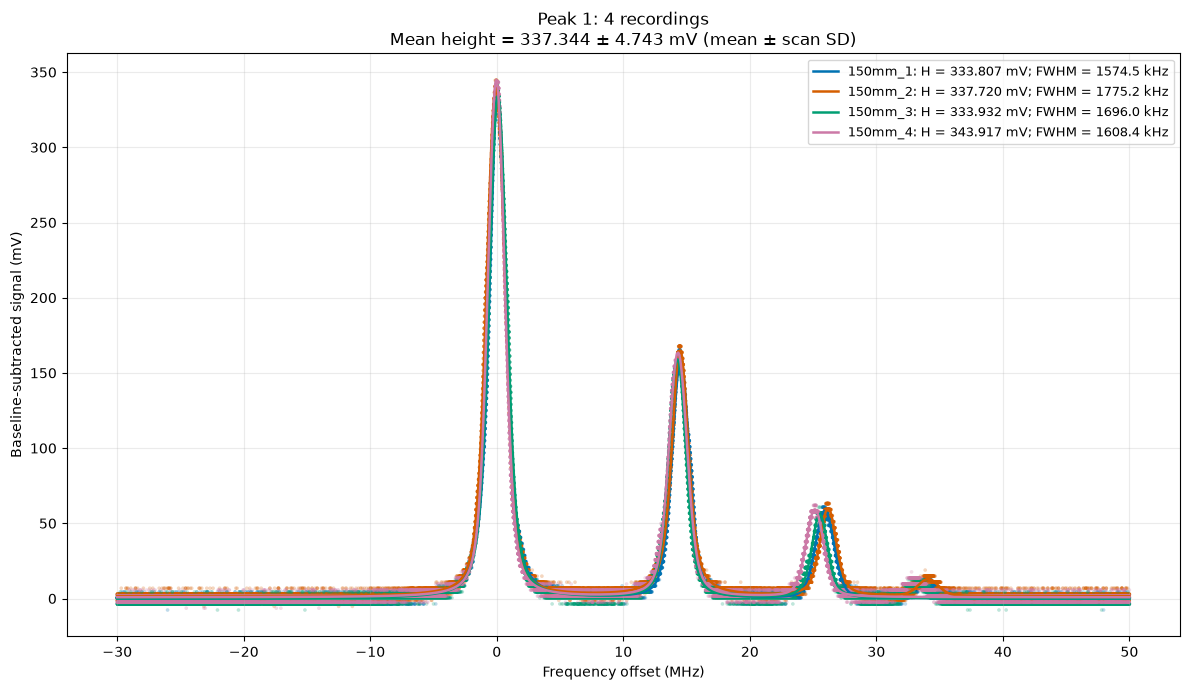

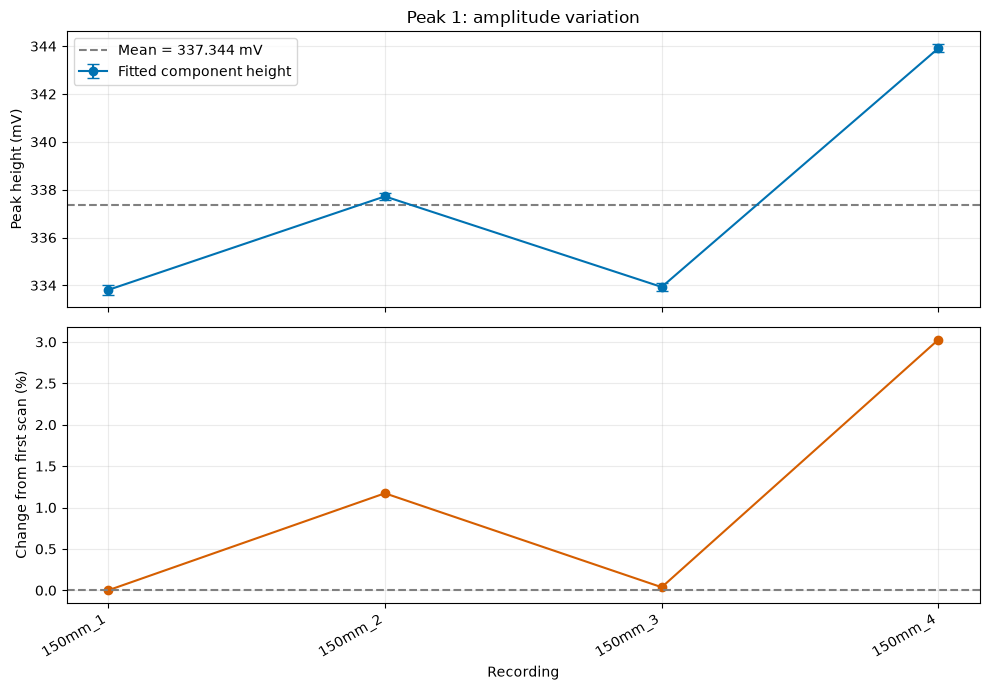

In [32]:
import csv
import re
import shutil
import tempfile
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.special import wofz


# ============================================================
# SETTINGS
# ============================================================

DATA_FOLDER = Path(
    "/Volumes/Physics-Photonics/Group/Compact components/"
    "2PAC/Data/20261123/27mW_2"
)

DATA_FILES = [
    DATA_FOLDER / f"150mm_{number}.csv"
    for number in range(1, 5)
]

CHANNEL = 2
REVERSE_SIGNAL = True
SIGNAL_POLARITY = 1

CROP_FRACTION = (0.2, 0.8)
FIT_RANGE_MHZ = (-30, 50)

PEAK_HEIGHT = 0.3
PEAK_WIDTH_SAMPLES = 10
PEAK_DISTANCE_FRACTION = 0.05

CALIBRATION_SEPARATION_MHZ = 14.412
CALIBRATION_PAIR = None
SHOW_CALIBRATION_PLOTS = False

ALIGN_TO_SELECTED_PEAK = False
PEAK_FOR_AVERAGE = 1

# True displays the spectra in mV so amplitude changes are visible.
# Assumes the CSV signal values are in volts.
PLOT_IN_MV = True

SAVE_RESULTS = True
MAX_FIT_EVALUATIONS = 80000

# Each component: area, centre, Gaussian sigma, Lorentzian HWHM.
# The area parameter is NOT the peak height.
INITIAL_GUESS = np.array([
    4.00,  0.5, 1.0, 1.0,
    2.00, 15.0, 1.0, 1.0,
    1.05, 25.0, 1.0, 1.0,
    1.00, 32.0, 1.0, 1.0,
    0.10,
], dtype=float)

COLORS = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
    "#E69F00",
]


# ============================================================
# READ CSV
# ============================================================

def clean_column_name(name):
    name = str(name).strip().lstrip("%#").strip().lower()
    name = re.sub(r"\([^)]*\)|\[[^]]*\]", "", name)
    return re.sub(r"[^a-z0-9]", "", name)


def read_scope_csv(file_path, channel):
    time_aliases = {"xaxis", "time", "times", "timeseconds"}
    header_row = None

    with file_path.open(
        "r", encoding="utf-8-sig", newline=""
    ) as handle:
        for row_number, row in enumerate(csv.reader(handle)):
            headings = [clean_column_name(value) for value in row]

            if any(value in time_aliases for value in headings):
                header_row = row_number
                break

    if header_row is None:
        raise ValueError(
            f"No time-column header found in {file_path.name}."
        )

    df = pd.read_csv(
        file_path,
        skiprows=header_row,
        encoding="utf-8-sig",
    )

    lookup = {
        clean_column_name(column): column
        for column in df.columns
    }

    time_column = next(
        (original for cleaned, original in lookup.items()
         if cleaned in time_aliases),
        None,
    )

    aliases = [
        str(channel),
        f"ch{channel}",
        f"channel{channel}",
        f"input{channel}",
        f"signal{channel}",
    ]

    signal_column = next(
        (lookup[alias] for alias in aliases if alias in lookup),
        None,
    )

    if time_column is None or signal_column is None:
        raise ValueError(
            f"Could not identify time and channel {channel}.\n"
            f"Available columns: {list(df.columns)}"
        )

    values = df[[time_column, signal_column]].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=float)

    values = values[np.isfinite(values).all(axis=1)]

    if len(values) < 50:
        raise ValueError("Too few valid numeric data points.")

    return values[:, 0], values[:, 1]


# ============================================================
# PREPROCESS AND CALIBRATE
# ============================================================

def extract_and_calibrate(time, signal, file_name):
    signal = SIGNAL_POLARITY * signal.copy()

    if REVERSE_SIGNAL:
        signal = np.flip(signal)

    start = int(CROP_FRACTION[0] * len(signal))
    stop = int(CROP_FRACTION[1] * len(signal))

    time = time[start:stop]
    signal = signal[start:stop]

    if len(signal) < 20:
        raise ValueError(
            f"{file_name}: too few samples after cropping."
        )

    signal = signal - np.mean(signal[:10])

    # IMPORTANT: retain the voltage scale before normalisation.
    normalisation_scale_V = np.max(signal)

    if normalisation_scale_V <= 0:
        raise ValueError(
            f"{file_name}: no positive peak. "
            "Check SIGNAL_POLARITY."
        )

    signal = signal / normalisation_scale_V

    peaks, _ = find_peaks(
        signal,
        height=PEAK_HEIGHT,
        width=PEAK_WIDTH_SAMPLES,
        distance=max(
            1, int(len(signal) * PEAK_DISTANCE_FRACTION)
        ),
    )

    if len(peaks) < 2:
        raise ValueError(
            f"{file_name}: only {len(peaks)} calibration peaks."
        )

    if CALIBRATION_PAIR is None:
        first, second = peaks[0], peaks[-1]
        selected_numbers = (1, len(peaks))

        if len(peaks) > 2:
            print(
                f"WARNING: {file_name}: {len(peaks)} calibration "
                "candidates; using first and last. Check this pair."
            )
    else:
        pair = np.asarray(CALIBRATION_PAIR)

        if (
            pair.shape != (2,)
            or not np.issubdtype(pair.dtype, np.integer)
            or pair[0] == pair[1]
            or np.any(pair < 1)
            or np.any(pair > len(peaks))
        ):
            raise ValueError("Invalid CALIBRATION_PAIR.")

        first, second = np.sort(peaks[pair - 1])
        selected_numbers = tuple(sorted(pair))

    print(
        f"{file_name}: calibration peaks {selected_numbers}; "
        f"normalisation scale = "
        f"{normalisation_scale_V * 1000:.3f} mV"
    )

    if SHOW_CALIBRATION_PLOTS:
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(time, signal, color="black")
        ax.scatter(time[peaks], signal[peaks], color="red")

        for number, index in enumerate(peaks, start=1):
            ax.annotate(
                str(number),
                (time[index], signal[index]),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
            )

        ax.scatter(
            time[[first, second]],
            signal[[first, second]],
            s=100,
            facecolors="none",
            edgecolors="blue",
            label="Selected pair",
        )

        ax.set(
            xlabel="Time (s)",
            ylabel="Normalised signal",
            title=f"Calibration: {file_name}",
        )
        ax.legend()
        ax.grid(alpha=0.3)
        fig.tight_layout()

    delta_time = time[second] - time[first]

    if delta_time == 0:
        raise ValueError("Calibration peaks have identical times.")

    frequency = (
        -(time - time[second])
        * CALIBRATION_SEPARATION_MHZ / delta_time
    )

    keep = (
        (frequency > FIT_RANGE_MHZ[0])
        & (frequency < FIT_RANGE_MHZ[1])
    )

    frequency = frequency[keep]
    signal = signal[keep]

    if len(frequency) <= len(INITIAL_GUESS):
        raise ValueError("Too few points in the fitting range.")

    order = np.argsort(frequency)

    return (
        frequency[order],
        signal[order],
        normalisation_scale_V,
    )


# ============================================================
# VOIGT MODEL
# ============================================================

def voigt_onepeak(x, area, centre, sigma, gamma):
    z = ((x - centre) + 1j * gamma) / (sigma * np.sqrt(2))

    return (
        area * np.real(wofz(z))
        / (sigma * np.sqrt(2 * np.pi))
    )


def voigt_bkgd(x, *parameters):
    model = np.full_like(x, parameters[-1], dtype=float)

    for peak_index in range(4):
        offset = 4 * peak_index
        model += voigt_onepeak(
            x, *parameters[offset:offset + 4]
        )

    return model


# ============================================================
# LINEWIDTH RESULTS
# ============================================================

def linewidth_results(sigma, gamma, width_covariance):
    gaussian_factor = 2 * np.sqrt(2 * np.log(2))

    gaussian_fwhm = gaussian_factor * sigma
    lorentzian_fwhm = 2 * gamma

    root = np.sqrt(
        0.2169 * lorentzian_fwhm**2 + gaussian_fwhm**2
    )

    voigt_fwhm = 0.5343 * lorentzian_fwhm + root

    gradients = {
        "Gaussian": np.array([gaussian_factor, 0.0]),
        "Lorentzian": np.array([0.0, 2.0]),
        "Voigt": np.array([
            gaussian_factor * gaussian_fwhm / root,
            2 * (
                0.5343
                + 0.2169 * lorentzian_fwhm / root
            ),
        ]),
    }

    widths = {
        "Gaussian": gaussian_fwhm,
        "Lorentzian": lorentzian_fwhm,
        "Voigt": voigt_fwhm,
    }

    output = {}

    for name, width in widths.items():
        gradient = gradients[name]

        if np.isfinite(width_covariance).all():
            variance = gradient @ width_covariance @ gradient
            error = np.sqrt(max(0.0, variance))
        else:
            error = np.nan

        output[f"{name}_FWHM_kHz"] = width * 1000
        output[f"{name}_FWHM_error_kHz"] = error * 1000

    return output


# ============================================================
# FITTED PEAK HEIGHT AND UNCERTAINTY
# ============================================================

def peak_height_results(
    area, sigma, gamma, height_covariance, scale_V
):
    """
    Height of one fitted Voigt component above its background.

    Uses area, sigma and gamma, including their fit covariance.
    The normalisation scale is treated as fixed.
    """
    values = np.array([area, sigma, gamma], dtype=float)

    def height(p):
        a, s, g = p
        return float(
            voigt_onepeak(
                np.array([0.0]), a, 0.0, s, g
            )[0]
        )

    height_normalised = height(values)
    gradient = np.zeros(3)

    for j in range(3):
        step = max(abs(values[j]) * 1e-5, 1e-8)

        upper = values.copy()
        upper[j] += step

        if values[j] - step > 0:
            lower = values.copy()
            lower[j] -= step

            gradient[j] = (
                height(upper) - height(lower)
            ) / (2 * step)
        else:
            gradient[j] = (
                height(upper) - height_normalised
            ) / step

    if np.isfinite(height_covariance).all():
        variance = gradient @ height_covariance @ gradient
        height_error_normalised = np.sqrt(max(0.0, variance))
    else:
        height_error_normalised = np.nan

    return {
        "Peak_height_normalised": height_normalised,
        "Peak_height_mV": height_normalised * scale_V * 1000,
        "Peak_height_fit_error_mV":
            height_error_normalised * scale_V * 1000,
    }


# ============================================================
# FIT ONE RECORDING
# ============================================================

def fit_recording(file_path):
    print(f"\n{'=' * 60}\nFitting {file_path.name}")

    with tempfile.TemporaryDirectory(
        prefix="rb_scope_data_"
    ) as temporary_folder:
        local_file = Path(temporary_folder) / file_path.name
        shutil.copy2(file_path, local_file)
        time, raw_signal = read_scope_csv(local_file, CHANNEL)

    frequency, signal, scale_V = extract_and_calibrate(
        time, raw_signal, file_path.name
    )

    lower_bounds = [0, -np.inf, 1e-9, 0] * 4 + [0]
    upper_bounds = [np.inf] * len(INITIAL_GUESS)

    parameters, covariance = curve_fit(
        voigt_bkgd,
        frequency,
        signal,
        p0=INITIAL_GUESS.copy(),
        bounds=(lower_bounds, upper_bounds),
        maxfev=MAX_FIT_EVALUATIONS,
    )

    # Preserve original parameter-block numbering.
    # Do not sort components by fitted centre.
    fitted_signal = voigt_bkgd(frequency, *parameters)
    residuals = signal - fitted_signal
    rms = np.sqrt(np.mean(residuals**2))

    rows = []

    for peak_index in range(4):
        offset = 4 * peak_index
        area, centre, sigma, gamma = (
            parameters[offset:offset + 4]
        )

        widths = linewidth_results(
            sigma,
            gamma,
            covariance[
                offset + 2:offset + 4,
                offset + 2:offset + 4,
            ],
        )

        # Height depends on area, sigma and gamma.
        indices = [offset, offset + 2, offset + 3]

        amplitudes = peak_height_results(
            area,
            sigma,
            gamma,
            covariance[np.ix_(indices, indices)],
            scale_V,
        )

        rows.append({
            "File": file_path.name,
            "Peak": peak_index + 1,
            "Centre_MHz": centre,
            "Area_normalised_MHz": area,
            "Area_V_MHz": area * scale_V,
            "Gaussian_sigma_MHz": sigma,
            "Lorentzian_gamma_MHz": gamma,
            "Normalisation_scale_V": scale_V,
            **widths,
            **amplitudes,
            "Residual_RMS": rms,
        })

    print(pd.DataFrame(rows)[[
        "Peak",
        "Centre_MHz",
        "Voigt_FWHM_kHz",
        "Peak_height_mV",
        "Peak_height_fit_error_mV",
    ]].to_string(index=False))

    selected = rows[PEAK_FOR_AVERAGE - 1]

    return {
        "file": file_path,
        "frequency": frequency,
        "signal": signal,
        "scale_V": scale_V,
        "parameters": parameters,
        "fitted_signal": fitted_signal,
        "residuals": residuals,
        "rows": rows,
        "selected_peak": selected,
        "display_shift": (
            selected["Centre_MHz"]
            if ALIGN_TO_SELECTED_PEAK else 0.0
        ),
    }


# ============================================================
# MAIN
# ============================================================

def main():
    if not 1 <= PEAK_FOR_AVERAGE <= 4:
        raise ValueError("PEAK_FOR_AVERAGE must be 1–4.")

    missing = [str(p) for p in DATA_FILES if not p.is_file()]

    if missing:
        raise FileNotFoundError(
            "Missing files:\n" + "\n".join(missing)
        )

    recordings = [fit_recording(p) for p in DATA_FILES]

    results = pd.DataFrame([
        row
        for recording in recordings
        for row in recording["rows"]
    ])

    # Compare each component with the same component in the
    # first recording listed in DATA_FILES.
    reference_height = results.groupby(
        "Peak", sort=False
    )["Peak_height_mV"].transform("first")

    valid_reference = reference_height.where(
        reference_height > 0
    )

    results["Height_change_mV"] = (
        results["Peak_height_mV"] - reference_height
    )

    results["Height_change_percent"] = (
        100 * (
            results["Peak_height_mV"] / valid_reference - 1
        )
    )

    selected = results.loc[
        results["Peak"] == PEAK_FOR_AVERAGE
    ].copy()

    heights = selected["Peak_height_mV"].to_numpy()
    widths = selected["Voigt_FWHM_kHz"].to_numpy()
    count = len(selected)

    mean_height = np.mean(heights)
    height_sd = (
        np.std(heights, ddof=1) if count > 1 else np.nan
    )

    mean_width = np.mean(widths)
    width_sd = (
        np.std(widths, ddof=1) if count > 1 else np.nan
    )

    print(
        f"\nPeak {PEAK_FOR_AVERAGE}: amplitude changes "
        f"relative to {DATA_FILES[0].name}"
    )

    print(selected[[
        "File",
        "Peak_height_mV",
        "Peak_height_fit_error_mV",
        "Height_change_mV",
        "Height_change_percent",
        "Voigt_FWHM_kHz",
    ]].round(4).to_string(index=False))

    print(
        f"\nMean peak height: {mean_height:.4f} mV"
        f"\nScan-to-scan height SD: {height_sd:.4f} mV"
        f"\nMean Voigt FWHM: {mean_width:.2f} kHz"
        f"\nScan-to-scan linewidth SD: {width_sd:.2f} kHz"
    )

    # ========================================================
    # OVERLAY SPECTRA AND FITS
    # ========================================================

    fig_overlay, ax = plt.subplots(figsize=(12, 7))

    for index, recording in enumerate(recordings):
        color = COLORS[index % len(COLORS)]
        frequency = recording["frequency"]
        shift = recording["display_shift"]
        peak = recording["selected_peak"]

        # Restore the original signal scale for amplitude plots.
        display_scale = (
            recording["scale_V"] * 1000
            if PLOT_IN_MV else 1.0
        )

        ax.scatter(
            frequency - shift,
            recording["signal"] * display_scale,
            s=7,
            alpha=0.25,
            color=color,
            edgecolors="none",
            rasterized=True,
        )

        dense_frequency = np.linspace(
            frequency.min(), frequency.max(), 10000
        )

        ax.plot(
            dense_frequency - shift,
            voigt_bkgd(
                dense_frequency,
                *recording["parameters"],
            ) * display_scale,
            color=color,
            linewidth=1.8,
            label=(
                f"{recording['file'].stem}: "
                f"H = {peak['Peak_height_mV']:.3f} mV; "
                f"FWHM = {peak['Voigt_FWHM_kHz']:.1f} kHz"
            ),
        )

    ax.set_title(
        f"Peak {PEAK_FOR_AVERAGE}: {count} recordings\n"
        f"Mean height = {mean_height:.3f} ± {height_sd:.3f} mV "
        f"(mean ± scan SD)"
    )

    ax.set_xlabel(
        f"Frequency relative to Peak {PEAK_FOR_AVERAGE} (MHz)"
        if ALIGN_TO_SELECTED_PEAK
        else "Frequency offset (MHz)"
    )

    ax.set_ylabel(
        "Baseline-subtracted signal (mV)"
        if PLOT_IN_MV else "Normalised signal"
    )

    ax.legend(fontsize=9)
    ax.grid(alpha=0.25)
    fig_overlay.tight_layout()

    # ========================================================
    # PEAK HEIGHT AND PERCENTAGE CHANGE
    # ========================================================

    scan_numbers = np.arange(1, count + 1)

    fig_amplitude, (ax_height, ax_change) = plt.subplots(
        2, 1,
        figsize=(10, 7),
        sharex=True,
    )

    ax_height.errorbar(
        scan_numbers,
        selected["Peak_height_mV"],
        yerr=selected["Peak_height_fit_error_mV"],
        fmt="o-",
        color=COLORS[0],
        capsize=4,
        label="Fitted component height",
    )

    ax_height.axhline(
        mean_height,
        color="grey",
        linestyle="--",
        label=f"Mean = {mean_height:.3f} mV",
    )

    ax_height.set_ylabel("Peak height (mV)")
    ax_height.set_title(
        f"Peak {PEAK_FOR_AVERAGE}: amplitude variation"
    )
    ax_height.legend()
    ax_height.grid(alpha=0.25)

    ax_change.plot(
        scan_numbers,
        selected["Height_change_percent"],
        "o-",
        color=COLORS[1],
    )

    ax_change.axhline(0, color="grey", linestyle="--")
    ax_change.set_ylabel("Change from first scan (%)")
    ax_change.set_xlabel("Recording")

    ax_change.set_xticks(
        scan_numbers,
        [Path(name).stem for name in selected["File"]],
        rotation=30,
        ha="right",
    )

    ax_change.grid(alpha=0.25)
    fig_amplitude.tight_layout()

    # ========================================================
    # SAVE RESULTS
    # ========================================================

    if SAVE_RESULTS:
        output_folder = (
            DATA_FOLDER / "FittingParams" / "Amplitude"
        )
        output_folder.mkdir(parents=True, exist_ok=True)

        timestamp = datetime.now().strftime(
            "%Y%m%d_%H%M%S_%f"
        )
        prefix = f"150mm_amplitude_{timestamp}"

        results.to_csv(
            output_folder / f"{prefix}_all_peaks.csv",
            index=False,
        )

        selected.to_csv(
            output_folder / f"{prefix}_selected_peak.csv",
            index=False,
        )

        fig_overlay.savefig(
            output_folder / f"{prefix}_overlay.png",
            dpi=300,
            bbox_inches="tight",
        )

        fig_amplitude.savefig(
            output_folder / f"{prefix}_changes.png",
            dpi=300,
            bbox_inches="tight",
        )

        print(f"\nSaved results to:\n{output_folder}")

    print(
        "\nPeak height excludes the fitted background and "
        "neighbouring components."
        "\nAmplitude error bars contain fit uncertainty only; "
        "normalisation-scale and instrument uncertainties "
        "are not included."
        "\nPositive percentage change means increased amplitude."
    )

    plt.show()


if __name__ == "__main__":
    main()